# ms-09: Does the beam deflector have a useful bandwidth?

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from dataclasses import asdict, replace
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
ROOT = Path.cwd()
if not (ROOT/'simulations').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'simulations'))
from design_studies import (Design, order_metrics, spectral_sweep, bandwidth,
                           local_prediction, optimize_widths, grcwa_check)
from unit_cell_te import Cell, solve_cell, sample_ey
plt.rcParams.update({'figure.dpi': 125, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
OUT = ROOT/'data/design-studies'; OUT.mkdir(parents=True, exist_ok=True)
def metadata(design):
    import scipy
    return dict(parameters=asdict(design), units='um, degrees; incident-normalized power',
      conventions='exp(-i omega t), TE Ey, r at z=0, t at z=height',
      sources={name:hashlib.sha256((ROOT/'simulations'/name).read_text(encoding='utf-8').encode()).hexdigest()
               for name in ['design_studies.py','unit_cell_te.py','metasurface_synthesis.py']},
      environment={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__})
def geometry(ax, design, title):
    L=len(design.widths_um)*design.pitch_um; h=design.height_um
    ax.add_patch(Rectangle((0,h),L,.32,fc='#c3ddeb'))
    for j,w in enumerate(design.widths_um):
        ax.add_patch(Rectangle(((j+.5)*design.pitch_um-w/2,0),w,h,fc='#167b9b',ec='white'))
        ax.text((j+.5)*design.pitch_um,-.07,str(j+1),ha='center',fontsize=9)
    ax.axvline(0,c='#9866aa',ls='--');ax.axvline(L,c='#9866aa',ls='--')
    ax.set(xlim=(-.1,L+.1),ylim=(h+.32,-.4),xlabel='x (um)',ylabel='z (um)',title=title)
    ax.text(.05,.04,'TE: E along y; k along +z',transform=ax.transAxes,fontsize=8)
    ax.text(.05,.13,'Repeated in x; invariant in y',transform=ax.transAxes,fontsize=8)


The same six-ridge supercell from Chapter 5 is frozen throughout the wavelength sweep. The geometry figure below is its x–z section. Light arrives from air along +z, with electric field along the invariant y direction; the substrate has index 1.5. The real indices are held constant, so this experiment measures **structural dispersion**, not measured material dispersion. Predict: does high total transmission imply high power in the desired +1 order?

See the [lab instructions](../labs/09-dispersion-lab.md). All figures are original calculated outputs. Plot labels and code are shared between editions.

In [2]:
# Physical inputs, performance requirements, and numerical controls are separate.
design = Design()
anchor_um = design.wavelength_um
wavelengths = np.linspace(1.36, 1.74, 161)  # Includes 1.55; avoids exact grazing at 1.4625.
efficiency_threshold = .80
angle_tolerance_deg = .5
M_compare, M_reference = 96, 144
coarse_harmonics = spectral_sweep(design, wavelengths, M_compare)
rows = spectral_sweep(design, wavelengths, M_reference)
max_power_change = max(abs(a['T']-b['T']) for a,b in zip(rows,coarse_harmonics))
assert max_power_change < 1e-3
assert max(r['balance_error'] for r in rows) < 1e-9
bands = []
for stride in [4,2,1]:
    subset=rows[::stride]
    bands.append(dict(samples=len(subset),efficiency=bandwidth(subset,anchor_um,efficiency_threshold),
        usable=bandwidth(subset,anchor_um,efficiency_threshold,angle_tolerance_deg)))
print('Maximum target-power change, M=96 to 144:',max_power_change)
print(json.dumps(bands,indent=2))


Maximum target-power change, M=96 to 144: 3.5677626034180676e-05
[
  {
    "samples": 41,
    "efficiency": {
      "lower_um": 1.4569873659616925,
      "upper_um": 1.5718956899902168,
      "width_um": 0.11490832402852424,
      "fractional_wavelength_width": 0.0741344025990479,
      "frequency_width_THz": 15.041553207100442,
      "left_clipped": false,
      "right_clipped": false
    },
    "usable": {
      "lower_um": 1.5007149527453871,
      "upper_um": 1.5718956899902168,
      "width_um": 0.07118073724482965,
      "fractional_wavelength_width": 0.04592305628698687,
      "frequency_width_THz": 9.046097240395135,
      "left_clipped": false,
      "right_clipped": false
    }
  },
  {
    "samples": 81,
    "efficiency": {
      "lower_um": 1.4571204614522646,
      "upper_um": 1.5718190138581414,
      "width_um": 0.11469855240587679,
      "fractional_wavelength_width": 0.0739990660683076,
      "frequency_width_THz": 15.013454942154938,
      "left_clipped": false,
     

Use the connected passing interval containing 1.55 µm. Interpolate each threshold crossing, and mark any boundary that reaches the scan edge as **clipped**. Narrow disconnected windows must not be merged. The useful band requires both target efficiency ≥0.8 and a beam direction within 0.5° of its design direction. Compare the 41-, 81- and 161-point grids before quoting edge precision.

Interpolate the efficiency and angular constraints separately, then intersect their connected intervals around the anchor. Interpolating the pointwise minimum of the margins can shift an edge when the limiting constraint switches between samples.


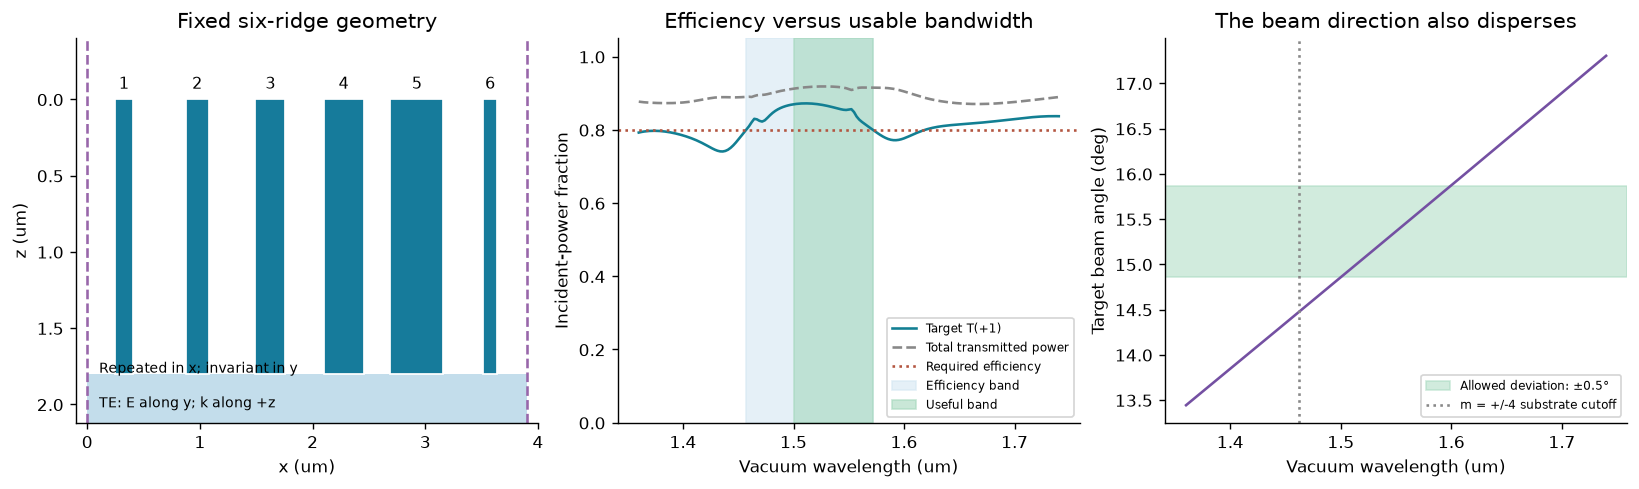

In [3]:
lam=np.array([r['wavelength_um'] for r in rows]); power=np.array([r['T'] for r in rows])
angles=np.array([r['angle_deg'] for r in rows]); i0=np.argmin(abs(lam-anchor_um))
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
geometry(ax[0],design,'Fixed six-ridge geometry')
ax[1].plot(lam,power,label='Target T(+1)',c='#127f93')
ax[1].plot(lam,[r['total_T'] for r in rows],label='Total transmitted power',c='#888',ls='--')
ax[1].axhline(efficiency_threshold,c='#b35540',ls=':',label='Required efficiency')
for band,color,label in [(bands[-1]['efficiency'],'#d4e7f3','Efficiency band'),(bands[-1]['usable'],'#a5d8bd','Useful band')]:
    if band: ax[1].axvspan(band['lower_um'],band['upper_um'],color=color,alpha=.6,label=label)
ax[1].set(xlabel='Vacuum wavelength (um)',ylabel='Incident-power fraction',ylim=(0,1.05),title='Efficiency versus usable bandwidth')
ax[1].legend(fontsize=7)
ax[2].plot(lam,angles,c='#7450a2');ax[2].axhspan(angles[i0]-angle_tolerance_deg,angles[i0]+angle_tolerance_deg,color='#a5d8bd',alpha=.5,label=f'Allowed deviation: ±{angle_tolerance_deg:g}°')
ax[2].axvline(1.4625,c='#888',ls=':',label='m = +/-4 substrate cutoff')
ax[2].set(xlabel='Vacuum wavelength (um)',ylabel='Target beam angle (deg)',title='The beam direction also disperses')
ax[2].legend(fontsize=7)
plt.show()


For exp(−iωt), the face-referenced modal group delay is d arg(t₊₁)/dω. It is not the transit time to an arbitrary detector. Differentiate against angular frequency in ascending order, not wavelength. Mask weak transmission and compare frequency derivatives from separate spectral grids. A power-converged curve need not have a converged derivative. The shaded plot above is a performance bandwidth, not a resonance FWHM.

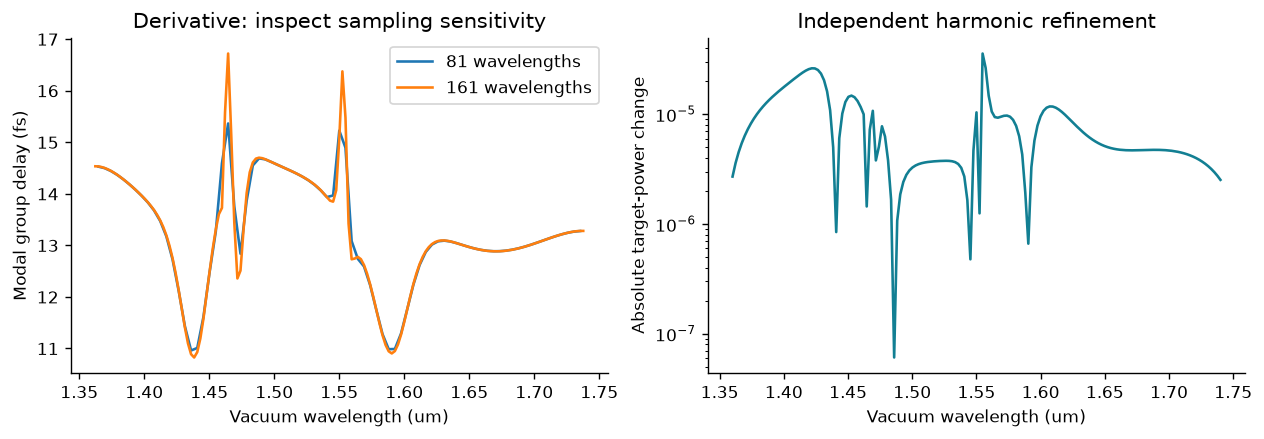

139095

In [4]:
def modal_delay(selected):
    ls=np.array([r['wavelength_um'] for r in selected])[::-1]
    ts=np.array([complex(r['t_real'],r['t_imag']) for r in selected])[::-1]
    omega=2*np.pi*.299792458/ls  # rad/fs; c in um/fs
    phase=np.unwrap(np.angle(ts))
    delay=np.gradient(phase,omega,edge_order=2)
    valid=np.array([r['T'] for r in selected])[::-1]>.05
    # Also mask derivative stencils touching a weak sample.
    valid[1:-1] &= valid[:-2].copy() & valid[2:].copy()
    valid[[0,-1]]=False
    return ls,np.where(valid,delay,np.nan)
fig,ax=plt.subplots(1,2,figsize=(10,3.4),layout='constrained')
for stride in [2,1]:
    ls,delay=modal_delay(rows[::stride]); ax[0].plot(ls,delay,label=f'{len(ls)} wavelengths')
ax[0].set(xlabel='Vacuum wavelength (um)',ylabel='Modal group delay (fs)',title='Derivative: inspect sampling sensitivity');ax[0].legend()
ax[1].semilogy(lam,np.maximum(abs(power-np.array([r['T'] for r in coarse_harmonics])),1e-16),c='#127f93')
ax[1].set(xlabel='Vacuum wavelength (um)',ylabel='Absolute target-power change',title='Independent harmonic refinement')
plt.show()
report=dict(metadata=metadata(design),half_orders=[M_compare,M_reference],rows=rows,
    comparison=coarse_harmonics,bandwidths=bands,efficiency_threshold=efficiency_threshold,
    angle_tolerance_deg=angle_tolerance_deg,max_power_change=max_power_change)
(OUT/'dispersion.json').write_text(json.dumps(report,indent=2)+'\n')


**Submit:** threshold and scan definition, band edges with grid sensitivity, target-order and total-power curves, and the fixed geometry. Add a causal material model only as a separately documented extension; do not call this constant-index calculation an experimentally validated achromatic device.